# Minecraft World Generation

In [2]:
import matplotlib.pyplot as plt
import numpy as np

In [3]:
AIR =   '#00000000'
GRASS = '#489e09ff'
ROCK =  '#848685ff'
WATER = '#0384fc44'
WOOD = '#5e4211ff'
LEAVES = '#5ca90488'
CHERRY_LEAVES = '#ffc4f588'
DIRT = '#733c21ff'
IRON = '#CD9671ff'
COAL = '#343434ff'
DIAMOND = '#5cd9ff44'

COLORS = np.array([ AIR, GRASS, ROCK, WATER, WOOD, LEAVES, CHERRY_LEAVES, DIRT, IRON, COAL, DIAMOND ])

COLOR_MAP = {
    'AIR': 0,
    'GRASS': 1,
    'ROCK': 2,
    'WATER': 3,
    'WOOD': 4,
    'LEAVES': 5,
    'CHERRY_LEAVES': 6,
    'DIRT': 7,
    'IRON': 8,
    'COAL': 9,
    'DIAMOND': 10,
}

WIDTH = 16
DEPTH = 16
HEIGHT = 48

In [4]:
def render(arr, title=''):
    width, depth, height = arr.shape

    X = np.arange(width, dtype=np.int8)
    Y = np.arange(depth, dtype=np.int8)
    Z = np.arange(height, dtype=np.int8)

    x, y, z = np.meshgrid(X, Y, Z)
    x, y, z = y.reshape(-1), x.reshape(-1), z.reshape(-1) # x and y is flipped because the plotting is flipped 180 so the z increases downwards

    # Magic
    if width == WIDTH and height == HEIGHT and depth == DEPTH:
        m = np.full((8, 8), fill_value=COLOR_MAP['GRASS'])
        m[np.unravel_index([17, 18, 21,22, 25, 26, 29, 30, 35, 36, 42, 43, 44, 45, 50, 51, 52, 53, 58, 61], shape=m.shape, order='C')] = COLOR_MAP['COAL']
        arr[4:12,4:12, HEIGHT-1:HEIGHT] = np.rot90(m[:,:,None], k=2)

    # Create a 3D plot
    ax = plt.figure(figsize=[10, 40]).add_subplot(111, projection='3d')

    color=COLORS[arr.reshape(-1)]

    ax.set_proj_type('ortho')
    ax.set_box_aspect((width , depth , height ))

    ax.bar3d(x, y, z, 1, 1, 1, color=color)
    elev, azim, roll = ax.elev, ax.azim, ax.roll
    ax.view_init(elev+180, azim+15, roll)

    # Set labels and title
    ax.set_xlabel('X')
    ax.set_xticks(X)
    ax.set_ylabel('Y')
    ax.set_yticks(Y)
    ax.set_zlabel('Z')
    ax.set_zticks(Z)
    ax.set_autoscalez_on(8)
    plt.title(title)

    # Show the plot
    plt.show()

# Fill the chunk with stone starting at height 10.

- np.zeros
- slicing
- dtype

# Generate terrain

For the generation, use the $2\sin(x)$ function on the $[0, 6]$ interval as shown below:

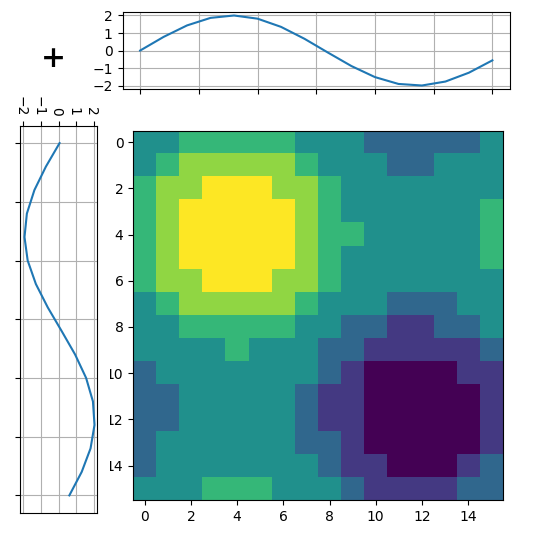

- np.linspace
- np.sin
- reshape
- astype
- T

- np.arange
- masking
- new axis

# Make the blocks above the average level grassy

- np.mean
- masking

# Fill the areas below the average level with water.

- slicing
- masking
- operations on a slice

# Create trees based on the diagram below.

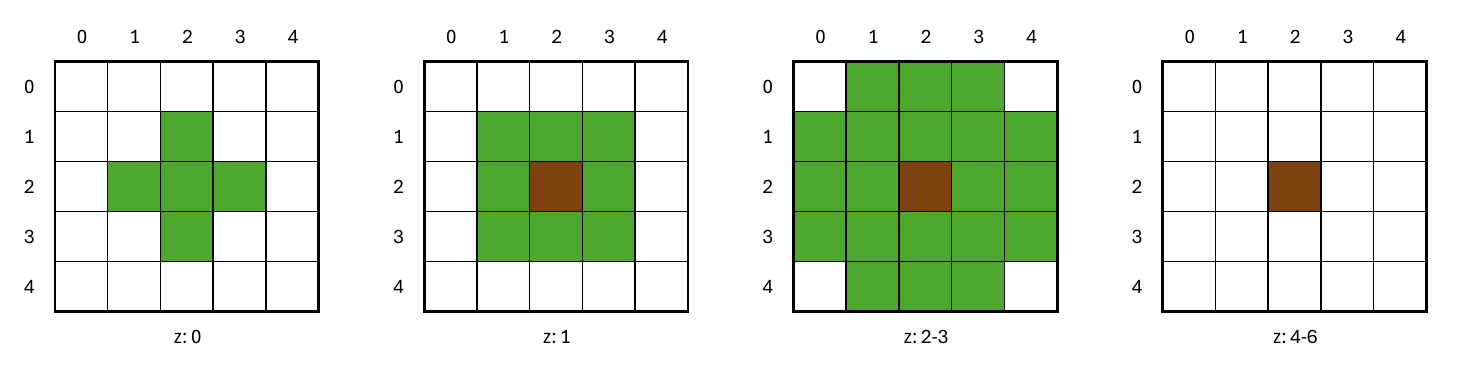

- np.full
- slicing along multiple axes

# Clone the tree and create a cherry blossom tree.

- ndarray.copy
- ndarray.view
- np.shares_memory

# Give the trees some personality.

- np.random.shuffle
- copy

- np.random.shuffle
- indexing
- np.arange
- copy

# Place the trees on the terrain.

- astype
- indexing
- copying into a slice

# Create caves in the stone layer.

1. One cave between layers 20–27.
2. One cave between layers 30–37.

- slicing

# Generate ores in the cave areas.

- Place coal with a random distribution in every second layer of the upper cave area.
- Place iron ore with a random distribution in every second layer of the lower cave area.
- Ores should generate at any given index with a 60% probability.

basic -> advanced - works

- np.random.choice
- slicing
- copy

basic -> advanced -> advanced - does not work

- copy
- masking
- difference between basic and advanced indexing

- view
- slicing
- random.choice
- masking

# Place 15 diamond blocks randomly between layers 40 and 45.

- np.random.randint
- np.unravel_index
- slicing
- view
- how slicing works

- np.random.randint
- slicing
- view
- how slicing works

# Implement the *X-ray* function so we can see inside the chunk.